# 06 · Fitur Unik 2: Deteksi Input di Luar Domain (*Out-of-Domain*)
## Estimasi Harga Rumah California dengan MLP Regresi

MLP selalu mengeluarkan **satu angka**, apa pun inputnya. Fitur ini memeriksa input **sebelum** diprediksi: apakah kombinasi nilainya mirip dengan
blok sensus yang pernah dilihat model? Bila tidak, input ditandai **"di luar domain"**, disertai skor dan fitur penyebab utamanya, supaya pengguna
tahu bahwa angka prediksinya hasil ekstrapolasi, bukan hasil belajar dari data yang mirip.

Notebook 05 menjawab pertanyaan "seberapa besar model bisa meleset?" (interval prediksi). Notebook ini menjawab pertanyaan yang berbeda:
**"apakah model pantas ditanya hal ini?"**

### Pemetaan ke ketentuan fitur unik

| Unsur yang diminta | Bagian |
|---|---|
| Apa fiturnya | 1 |
| Mengapa dibutuhkan | 2 |
| Bagaimana implementasinya | 3 (detektor, pemilihan metode dan ambang, fungsi `cek_domain`) dan 5 (penyimpanan, integrasi) |
| Bukti dampaknya | 4 (positif palsu, deteksi per skenario, kegagalan senyap, galat data nyata, kestabilan) |

### Protokol

| # | Aturan | Alasan |
|---|---|---|
| 1 | Statistik detektor (rata-rata, kovarians, rentang) dan ambang dihitung dari **train** saja | Sama seperti preprocessing: tidak ada informasi val/test yang bocor |
| 2 | Metode dan persentil ambang dipilih **hanya dari validation**, dengan aturan yang ditulis sebelum hasil dilihat (bagian 3.2) | Menghindari memilih metode karena kebetulan bagus di test |
| 3 | Input yang diuji harus **lolos validasi rentang API** (`HouseInput` di `backend/app.py`) | Input ekstrem sudah ditolak API; yang belum tertangani hanya input yang lolos tetapi tidak wajar |
| 4 | Skenario dibagi tiga: **tidak wajar** (jelas keliru), **halus** (sulit), **diblokir** (sudah ditolak API). Skenario halus **tidak** ikut menentukan pilihan metode dan dilaporkan terpisah | Kegagalan pada kasus sulit tidak boleh disembunyikan di dalam rata-rata |
| 5 | Test dipakai mulai bagian 4, hanya untuk melaporkan | Tidak ada keputusan yang diubah berdasarkan test |

## 0. Setup

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import warnings
from datetime import date
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tensorflow import keras

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- Pengaturan -------------------------------------------------------------------------
SEED = 42
PCTLS = [95.0, 99.0, 99.5, 99.9]   # persentil jarak train yang dicoba sebagai ambang
FPR_MAX = 1.5                      # batas positif palsu pada validation (%), DITETAPKAN sebelum melihat hasil
N_SCEN = 500                       # jumlah baris dasar per skenario
N_REPEAT = 100                     # jumlah pembagian ulang acak pada uji kestabilan
TARGET_SCALE = 100_000.0
TARGET = "median_house_value"

# ---- Lokasi proyek (pola sama dengan notebook 05) ---------------------------------------
IN_COLAB = "google.colab" in sys.modules
REPO_NAME = "california-house-price-mlp"
REPO_URL = f"https://github.com/lukito789/{REPO_NAME}.git"   # ganti jika username/nama repo berbeda

if IN_COLAB:
    ROOT = Path("/content") / REPO_NAME
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
else:
    ROOT = Path.cwd()
    if not (ROOT / "data" / "housing.csv").exists():
        ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "housing.csv"
PROC_PATH = ROOT / "data" / "processed" / "housing_processed.npz"
ART = ROOT / "backend" / "artifacts"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "data" / "processed"      # hasil notebook disimpan bersama keluaran notebook 02 dan 03
for d_ in (FIG_DIR, MODEL_DIR):
    d_.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


# preprocess.py milik backend dipakai agar input diproses PERSIS seperti di API
sys.path.insert(0, str(ROOT / "backend"))
import preprocess as bp

prep = json.loads((ART / "prep.json").read_text())
NUM_NAMES = list(bp.NUMERIC)
NUM_IDX = list(range(len(NUM_NAMES)))      # 8 kolom pertama hasil transform = fitur numerik terstandardisasi

# ---- Data: pembagian identik dengan notebook 02 (seed 42, 70/15/15) -----------------------
raw = pd.read_csv(DATA_PATH).dropna(subset=[TARGET, "ocean_proximity"]).reset_index(drop=True)
shuf = raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n_all = len(shuf); n_tr, n_va = int(n_all * 0.70), int(n_all * 0.15)
train_df = shuf.iloc[:n_tr].reset_index(drop=True)
val_df = shuf.iloc[n_tr:n_tr + n_va].reset_index(drop=True)
test_df = shuf.iloc[n_tr + n_va:].reset_index(drop=True)

X_train, X_val, X_test = (bp.transform(d, prep) for d in (train_df, val_df, test_df))
y_val = val_df[TARGET].to_numpy(); y_test = test_df[TARGET].to_numpy()

if PROC_PATH.exists():
    ref = np.load(PROC_PATH, allow_pickle=True)
    same = all(np.allclose(a, ref[k], atol=1e-5) for a, k in zip((X_train, X_val, X_test), ("X_train", "X_val", "X_test")))
    print("Fitur dari backend/preprocess.py == housing_processed.npz (notebook 02):", same)
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,} | fitur numerik dipakai detektor: {NUM_NAMES}")

# ---- Model yang dipakai aplikasi ----------------------------------------------------------
model = None
for p in (ART / "model.keras", ROOT / "data" / "processed" / "mlp_notebook03.keras"):
    if p.exists():
        try:
            m = keras.models.load_model(p)
            if m.input_shape[-1] == X_train.shape[1]:
                model, model_path = m, p
                break
        except Exception as err:
            print(f"[gagal memuat] {p.relative_to(ROOT)}: {err}")
if model is None:
    raise FileNotFoundError("Tidak ada model yang bisa dimuat. Jalankan backend/train.py atau notebook 03 terlebih dahulu.")
print("Model:", model_path.relative_to(ROOT), "| Keras", keras.__version__)


def prediksi_usd(df):
    """Prediksi seperti di API: dipotong minimal 0 (lihat backend/app.py)."""
    v = model(bp.transform(df, prep), training=False).numpy().ravel() * TARGET_SCALE
    return np.maximum(v, 0.0)

I0000 00:00:1793766241.792360     116 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793766247.296051     116 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Fitur dari backend/preprocess.py == housing_processed.npz (notebook 02): True
train 14,447 | val 3,096 | test 3,097 | fitur numerik dipakai detektor: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']


Model: backend/artifacts/model.keras | Keras 3.15.1


## 1. Apa Fiturnya

**Deteksi input di luar domain** memberi tiga keluaran tambahan untuk setiap permintaan prediksi:

| Keluaran | Arti |
|---|---|
| `skor` | Jarak Mahalanobis input terhadap sebaran data latih. Makin besar, makin tidak lazim |
| `status` | `NORMAL` bila skor di bawah ambang, `DI LUAR DOMAIN` bila di atas |
| `penyebab` | Dua fitur yang paling menyumbang pada skor, untuk pesan peringatan yang bisa ditindaklanjuti |

**Jarak Mahalanobis** mengukur seberapa jauh sebuah titik dari pusat data, dengan memperhitungkan **sebaran dan korelasi antar-fitur**.
Berbeda dengan sekadar memeriksa rentang tiap fitur satu per satu, ia tahu bahwa `households` biasanya mengikuti `population`
dan bahwa `latitude` dan `longitude` bergerak bersama sepanjang garis pantai.

Fitur ini **tidak memblokir** prediksi. Prediksi tetap dikembalikan, tetapi disertai penanda bahwa angkanya tidak boleh dipercaya.

## 2. Mengapa Dibutuhkan

API sudah memvalidasi **rentang** tiap fitur (`HouseInput` di `backend/app.py`), jadi input ekstrem seperti koordinat Jakarta atau
`median_income` 38 sudah ditolak sebelum sampai ke model. Pertanyaannya: **apa yang lolos validasi tetapi tetap tidak wajar?**
Validasi per fitur tidak bisa melihat *kombinasi*: titik di laut lepas tetap berada di dalam kotak `latitude` 32 sampai 43 dan
`longitude` −125 sampai −113, dan `households` yang lebih besar dari `population` tetap lolos karena tiap angkanya berdiri sendiri valid.

Bagian ini membuat skenario dari baris **validation** (test belum disentuh) dan melihat apa yang dilakukan API dan model terhadapnya.

In [2]:
# Salinan aturan backend/app.py::HouseInput  (nilai: batas bawah, bawah inklusif?, batas atas)
APP_RULES = {
    "longitude": (-125, True, -113), "latitude": (32, True, 43), "housing_median_age": (1, True, 100),
    "total_rooms": (0, False, 50000), "total_bedrooms": (0, False, 10000), "population": (0, False, 40000),
    "households": (0, False, 10000), "median_income": (0, False, 20),
}
OCEAN_OK = set(bp.CATEGORIES)


def lolos_validasi(df):
    """True untuk baris yang akan DITERIMA API (tidak menghasilkan error 422)."""
    ok = df["ocean_proximity"].isin(OCEAN_OK).to_numpy().copy()
    for col, (lo, incl, hi) in APP_RULES.items():
        v = df[col]
        ok = ok & ((v >= lo) if incl else (v > lo)).to_numpy() & (v <= hi).to_numpy()
    return ok


print(f"Data nyata yang lolos validasi API -> train {lolos_validasi(train_df).mean() * 100:.1f}% | "
      f"val {lolos_validasi(val_df).mean() * 100:.1f}% | test {lolos_validasi(test_df).mean() * 100:.1f}%")
print(f"(Sisa di train = {int(train_df['total_bedrooms'].isna().sum())} baris dengan total_bedrooms kosong; API menolak nilai kosong.)")


# ---- Skenario input tidak lazim: tiap fungsi mengubah salinan baris dasar -----------------------------------
def _set(**kw):
    return lambda s, rng: s.assign(**kw)

def _acak(s, rng):                         # korelasi antar-fitur dirusak, tiap fitur tetap bernilai nyata
    s = s.copy()
    for c in NUM_NAMES:
        s[c] = rng.permutation(s[c].to_numpy())
    return s

SCEN = [  # (nama, kelompok, fungsi)
    ("Kontrol: data asli",                "kontrol",     lambda s, rng: s),
    ("Jakarta (-6,2; 106,8)",             "diblokir",    _set(latitude=-6.2, longitude=106.8)),
    ("median_income x10",                 "diblokir",    lambda s, rng: s.assign(median_income=s["median_income"] * 10)),
    ("Laut lepas (34,0; -124,0)",         "tidak wajar", _set(latitude=34.0, longitude=-124.0)),
    ("Idaho (42,5; -113,5)",              "tidak wajar", _set(latitude=42.5, longitude=-113.5)),
    ("households = 3 x population",       "tidak wajar", lambda s, rng: s.assign(households=s["population"] * 3)),
    ("total_bedrooms = 2 x total_rooms",  "tidak wajar", lambda s, rng: s.assign(total_bedrooms=s["total_rooms"] * 2)),
    ("Kolom diacak independen",           "tidak wajar", _acak),
    ("median_income = 15",                "halus",       _set(median_income=15.0)),
    ("latitude + 1,5 derajat",            "halus",       lambda s, rng: s.assign(latitude=s["latitude"] + 1.5)),
    ("ocean_proximity = ISLAND",          "halus",       _set(ocean_proximity="ISLAND")),
]
KELOMPOK = {nama: kel for nama, kel, _ in SCEN}


def bangun_skenario(base, seed):
    rng = np.random.default_rng(seed)
    out = {}
    for nama, kel, fn in SCEN:
        s = fn(base.copy(), rng)
        out[nama] = (kel, s, lolos_validasi(s))
    return out


base_val = val_df.sample(N_SCEN, random_state=SEED).reset_index(drop=True)
sk_val = bangun_skenario(base_val, SEED)

rows = []
for nama, (kel, s, ok) in sk_val.items():
    r = {"skenario": nama, "kelompok": kel, "lolos_API_%": ok.mean() * 100}
    if ok.any():
        pr = prediksi_usd(s[ok])
        r["median_prediksi_USD"] = np.median(pr)
        r["tampak_wajar_%"] = np.mean((pr >= 15_000) & (pr <= 500_001)) * 100
    rows.append(r)
tbl2 = pd.DataFrame(rows).set_index("skenario")
display(tbl2.round({"lolos_API_%": 1, "median_prediksi_USD": 0, "tampak_wajar_%": 1}))
print("tampak_wajar = prediksi antara $15.000 dan $500.001, yaitu rentang harga yang ada di data latih.")

Data nyata yang lolos validasi API -> train 98.6% | val 100.0% | test 100.0%
(Sisa di train = 207 baris dengan total_bedrooms kosong; API menolak nilai kosong.)


,kelompok,lolos_API_%,median_prediksi_USD,tampak_wajar_%
skenario,,,,
Kontrol: data asli,kontrol,100.0,174854.0,99.8
"Jakarta (-6,2; 106,8)",diblokir,0.0,NaN,NaN
median_income x10,diblokir,14.4,474002.0,88.9
"Laut lepas (34,0; -124,0)",tidak wajar,100.0,103368.0,99.8
"Idaho (42,5; -113,5)",tidak wajar,100.0,59668.0,100.0
households = 3 x population,tidak wajar,95.4,161941.0,100.0
total_bedrooms = 2 x total_rooms,tidak wajar,91.8,190625.0,100.0
Kolom diacak independen,tidak wajar,100.0,177192.0,99.2
median_income = 15,halus,100.0,482515.0,96.6


tampak_wajar = prediksi antara $15.000 dan $500.001, yaitu rentang harga yang ada di data latih.


**Yang dilihat dari tabel:**

- Skenario berkelompok **diblokir** hampir seluruhnya ditolak API: Jakarta 0% lolos, dan `median_income` ×10 hanya lolos untuk baris yang pendapatan
  awalnya kecil (hasilnya ≤ 20). Bagian itu sudah ditangani validasi dan bukan bahan fitur ini.
- Skenario **tidak wajar** sebagian besar lolos validasi (kolom `lolos_API_%`), sehingga sampai ke model. Kolom `tampak_wajar_%` menunjukkan masalahnya: model tetap mengeluarkan harga
  yang terlihat masuk akal untuk input yang tidak mungkin ada. Angka yang tampak wajar tetapi tidak dapat dipercaya jauh lebih berbahaya
  daripada angka yang jelas absurd, karena pengguna tidak punya alasan untuk curiga.
- Skenario **halus** disertakan sebagai ujian jujur: apakah detektor juga menangkap pergeseran kecil?

## 3. Implementasi

### 3.1 Detektor

`DomainDetector` dilatih dari **fitur numerik terstandardisasi pada train** (8 kolom; kolom one-hot `ocean_proximity` tidak dipakai karena
`ISLAND` hanya 5 baris sehingga kovariansnya hampir singular). Dua pemeriksaan tersedia:

| Pemeriksaan | Cara kerja |
|---|---|
| `rentang` | Ditandai bila **ada** fitur di luar nilai minimum atau maksimum train. Ini versi yang lebih ketat daripada validasi API |
| `mahalanobis` | Ditandai bila jarak Mahalanobis melebihi persentil ke-`p` dari jarak data train |
| `gabungan` | Ditandai bila salah satu di atas terpenuhi |

**Kontribusi per fitur.** Jarak kuadrat dapat diuraikan menjadi jumlah kontribusi per fitur: `c_j = d_j × (P·d)_j`, dengan `d` selisih terhadap rata-rata
dan `P` kebalikan matriks kovarians. Dua kontribusi terbesar dipakai sebagai `penyebab`.

In [3]:
class DomainDetector:
    def __init__(self, metode="mahalanobis", pct=99.0):
        assert metode in ("rentang", "mahalanobis", "gabungan")
        self.metode, self.pct = metode, pct

    def fit(self, Xnum):
        self.mu = Xnum.mean(axis=0)
        self.P = np.linalg.pinv(np.cov(Xnum, rowvar=False))
        self.lo, self.hi = Xnum.min(axis=0), Xnum.max(axis=0)
        self.thr = float(np.percentile(self.skor(Xnum), self.pct)) if self.metode != "rentang" else None
        return self

    def skor(self, Xnum):
        d = Xnum - self.mu
        return np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", d, self.P, d), 0.0))

    def luar_rentang(self, Xnum):
        return ((Xnum < self.lo) | (Xnum > self.hi)).any(axis=1)

    def flag(self, Xnum):
        if self.metode == "rentang":
            return self.luar_rentang(Xnum)
        m = self.skor(Xnum) > self.thr
        return m | self.luar_rentang(Xnum) if self.metode == "gabungan" else m

    def kontribusi(self, Xnum):
        d = Xnum - self.mu
        return d * (d @ self.P)            # tiap baris dijumlahkan = jarak kuadrat

    def nama(self):
        return self.metode if self.metode == "rentang" else f"{self.metode}_p{self.pct:g}"


def X_num(df):
    return bp.transform(df, prep)[:, NUM_IDX]


Xn_train, Xn_val, Xn_test = X_train[:, NUM_IDX], X_val[:, NUM_IDX], X_test[:, NUM_IDX]

# Uji kebenaran uraian kontribusi: jumlah per baris harus sama dengan jarak kuadrat
_t = DomainDetector("mahalanobis", 99).fit(Xn_train)
assert np.allclose(_t.kontribusi(Xn_val).sum(axis=1), _t.skor(Xn_val) ** 2, rtol=1e-3, atol=1e-3)
print("Uraian kontribusi per fitur konsisten dengan jarak Mahalanobis.")

Uraian kontribusi per fitur konsisten dengan jarak Mahalanobis.


### 3.2 Memilih metode dan ambang: hanya dari validation

**Aturan yang ditetapkan sebelum hasil dilihat:**

1. Hanya kandidat dengan **positif palsu pada validation ≤ 1,5%** yang boleh dipilih (positif palsu = data nyata yang salah ditandai). Batas ini
   menjaga agar peringatan tidak muncul untuk input yang sebenarnya wajar.
2. Dari yang memenuhi, pilih yang **rata-rata deteksinya tertinggi** pada skenario berkelompok **tidak wajar** (dibangun dari baris validation).
3. Bila masih seri, pilih yang positif palsunya lebih kecil, lalu yang lebih sederhana (`mahalanobis` sebelum `gabungan`).

Skenario **halus** dan **diblokir** tidak ikut menentukan pilihan.

In [4]:
sc_tw = [n for n, k in KELOMPOK.items() if k == "tidak wajar"]
val_sets = {n: X_num(sk_val[n][1][sk_val[n][2]]) for n in sc_tw}
print("Baris yang lolos validasi API per skenario (validation):", {n: len(v) for n, v in val_sets.items()})

cands = [DomainDetector("rentang")]
for m in ("mahalanobis", "gabungan"):
    cands += [DomainDetector(m, p) for p in PCTLS]

rows = []
for c in cands:
    c.fit(Xn_train)
    r = {"kandidat": c.nama(), "FPR_train_%": c.flag(Xn_train).mean() * 100, "FPR_val_%": c.flag(Xn_val).mean() * 100}
    for n, Xs in val_sets.items():
        r[n] = c.flag(Xs).mean() * 100
    r["deteksi_rata2_%"] = np.mean([r[n] for n in val_sets])
    rows.append(r)
sel = pd.DataFrame(rows).set_index("kandidat")
sel["memenuhi_FPR"] = sel["FPR_val_%"] <= FPR_MAX
display(sel.round(1))

elig = sel[sel["memenuhi_FPR"]].sort_values(["deteksi_rata2_%", "FPR_val_%"], ascending=[False, True])
best_name = elig.index[0]
DET = next(c for c in cands if c.nama() == best_name)
DET_RANGE = next(c for c in cands if c.metode == "rentang")
print(f"\nDipilih: {best_name} | ambang jarak = {DET.thr:.2f}" if DET.thr else f"\nDipilih: {best_name}")

Baris yang lolos validasi API per skenario (validation): {'Laut lepas (34,0; -124,0)': 500, 'Idaho (42,5; -113,5)': 500, 'households = 3 x population': 477, 'total_bedrooms = 2 x total_rooms': 459, 'Kolom diacak independen': 500}


,FPR_train_%,FPR_val_%,"Laut lepas (34,0; -124,0)","Idaho (42,5; -113,5)",households = 3 x population,total_bedrooms = 2 x total_rooms,Kolom diacak independen,deteksi_rata2_%,memenuhi_FPR
kandidat,,,,,,,,,
rentang,0.0,0.0,0.0,100.0,11.1,15.5,0.0,25.3,True
mahalanobis_p95,5.0,4.8,100.0,100.0,100.0,100.0,88.4,97.7,False
mahalanobis_p99,1.0,0.8,100.0,100.0,100.0,100.0,59.8,92.0,True
mahalanobis_p99.5,0.5,0.5,88.0,100.0,100.0,100.0,45.0,86.6,True
mahalanobis_p99.9,0.1,0.2,1.2,100.0,98.7,100.0,18.2,63.6,True
gabungan_p95,5.0,4.8,100.0,100.0,100.0,100.0,88.4,97.7,False
gabungan_p99,1.0,0.8,100.0,100.0,100.0,100.0,59.8,92.0,True
gabungan_p99.5,0.5,0.5,88.0,100.0,100.0,100.0,45.0,86.6,True
gabungan_p99.9,0.1,0.2,1.2,100.0,98.7,100.0,18.2,63.6,True



Dipilih: mahalanobis_p99 | ambang jarak = 7.26


Pembacaan tabel:

- `rentang` hanya menangkap skenario yang salah satu fiturnya benar-benar keluar dari rentang data latih (Idaho, karena `longitude` −113,5 lebih besar daripada nilai
  maksimum train). Pada skenario lain tiap fitur berada di dalam rentang, sehingga rata-ratanya rendah.
- Jarak Mahalanobis menangkap kombinasi yang janggal. Ada **trade-off ambang**: persentil 95 mendeteksi paling banyak tetapi melanggar batas positif palsu,
  sedangkan persentil 99,9 aman tetapi melewatkan banyak kasus.
- `gabungan` memberi hasil yang sama persis dengan `mahalanobis` pada persentil yang sama, artinya pemeriksaan rentang tidak menambah deteksi di sini,
  sehingga dipilih yang lebih sederhana.

### 3.3 Fungsi `cek_domain`

Fungsi berikut menerima baris data **mentah** (seperti input API), memprosesnya dengan `backend/preprocess.py`, lalu mengeluarkan skor, status, dan
penyebab utama. Fungsi ini **tidak membutuhkan Keras**, sehingga ringan dipasang di API.

In [5]:
def cek_domain(df_raw, det=None):
    det = det or DET
    X = X_num(df_raw)
    skor = det.skor(X)
    flag = det.flag(X)
    top = np.argsort(-det.kontribusi(X), axis=1)[:, :2]
    return pd.DataFrame({
        "skor": skor.round(2),
        "ambang": det.thr if det.thr is not None else np.nan,
        "status": np.where(flag, "DI LUAR DOMAIN", "NORMAL"),
        "penyebab": [", ".join(NUM_NAMES[j] for j in t) if f else "-" for t, f in zip(top, flag)],
    }, index=df_raw.index)


display(cek_domain(val_df.head(3)))

,skor,ambang,status,penyebab
0,2.83,7.264027,NORMAL,-
1,1.97,7.264027,NORMAL,-
2,2.66,7.264027,NORMAL,-


## 4. Bukti Dampak

Mulai dari sini **test dipakai**, hanya untuk melaporkan. Metode dan ambang sudah ditetapkan di 3.2 dan tidak diubah lagi. Skenario dibangun
dari 500 baris **test** yang berbeda dari baris dasar validation, dan hanya baris yang **lolos validasi API** yang diuji.

### 4.1 Positif palsu: seberapa sering data nyata salah ditandai?

In [6]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h


rows = []
for nama, Xn in [("train", Xn_train), ("validation", Xn_val), ("test", Xn_test)]:
    f = DET.flag(Xn); k, n = int(f.sum()), len(f); lo, hi = wilson(k, n)
    rows.append({"subset": nama, "ditandai": k, "jumlah": n, "FPR_%": k / n * 100, "CI95_bawah": lo * 100, "CI95_atas": hi * 100})
fpr_tbl = pd.DataFrame(rows).set_index("subset")
display(fpr_tbl.round({"FPR_%": 2, "CI95_bawah": 2, "CI95_atas": 2}))
fpr_test = float(fpr_tbl.loc["test", "FPR_%"])

,ditandai,jumlah,FPR_%,CI95_bawah,CI95_atas
subset,,,,,
train,145,14447,1.00,0.85,1.18
validation,26,3096,0.84,0.57,1.23
test,29,3097,0.94,0.65,1.34


Persentase pada **train** ditentukan oleh pilihan ambang (persentil ke-`p` berarti sekitar `100 − p`% data latih ikut ditandai), sehingga yang
informatif adalah validation dan test: ia menunjukkan apakah angka itu berlaku pada data yang tidak dipakai menentukan ambang.

### 4.2 Deteksi per skenario

In [7]:
base_test = test_df.sample(N_SCEN, random_state=SEED + 1).reset_index(drop=True)
sk_test = bangun_skenario(base_test, SEED + 1)

rows = []
for nama, (kel, s, ok) in sk_test.items():
    if not ok.any():
        rows.append({"skenario": nama, "kelompok": kel, "lolos_API": 0}); continue
    Xs = X_num(s[ok])
    f, fr = DET.flag(Xs), DET_RANGE.flag(Xs)
    lo, hi = wilson(int(f.sum()), len(f))
    rows.append({"skenario": nama, "kelompok": kel, "lolos_API": int(ok.sum()),
                 "rentang_train_%": fr.mean() * 100, "terpilih_%": f.mean() * 100,
                 "CI95_bawah": lo * 100, "CI95_atas": hi * 100,
                 "skor_median": float(np.median(DET.skor(Xs)))})
det_tbl = pd.DataFrame(rows).set_index("skenario")
order = {"kontrol": 0, "tidak wajar": 1, "halus": 2, "diblokir": 3}
det_tbl = det_tbl.sort_values("kelompok", key=lambda s: s.map(order), kind="stable")
display(det_tbl.round({"rentang_train_%": 1, "terpilih_%": 1, "CI95_bawah": 1, "CI95_atas": 1, "skor_median": 1}))
print("Skenario 'diblokir' sebagian besar ditolak API; angkanya hanya untuk baris yang lolos (kolom lolos_API) dan tidak ikut kesimpulan.")

,kelompok,lolos_API,rentang_train_%,terpilih_%,CI95_bawah,CI95_atas,skor_median
skenario,,,,,,,
Kontrol: data asli,kontrol,500,0.2,0.8,0.3,2.0,2.3
"Laut lepas (34,0; -124,0)",tidak wajar,500,0.2,100.0,99.2,100.0,9.3
"Idaho (42,5; -113,5)",tidak wajar,500,100.0,100.0,99.2,100.0,19.3
households = 3 x population,tidak wajar,475,13.9,100.0,99.2,100.0,16.1
total_bedrooms = 2 x total_rooms,tidak wajar,460,17.0,100.0,99.2,100.0,15.7
Kolom diacak independen,tidak wajar,500,0.2,60.8,56.5,65.0,8.4
median_income = 15,halus,500,0.2,97.8,96.1,98.8,9.1
"latitude + 1,5 derajat",halus,498,2.0,1.2,0.6,2.6,3.2
ocean_proximity = ISLAND,halus,500,0.2,0.8,0.3,2.0,2.3


Skenario 'diblokir' sebagian besar ditolak API; angkanya hanya untuk baris yang lolos (kolom lolos_API) dan tidak ikut kesimpulan.


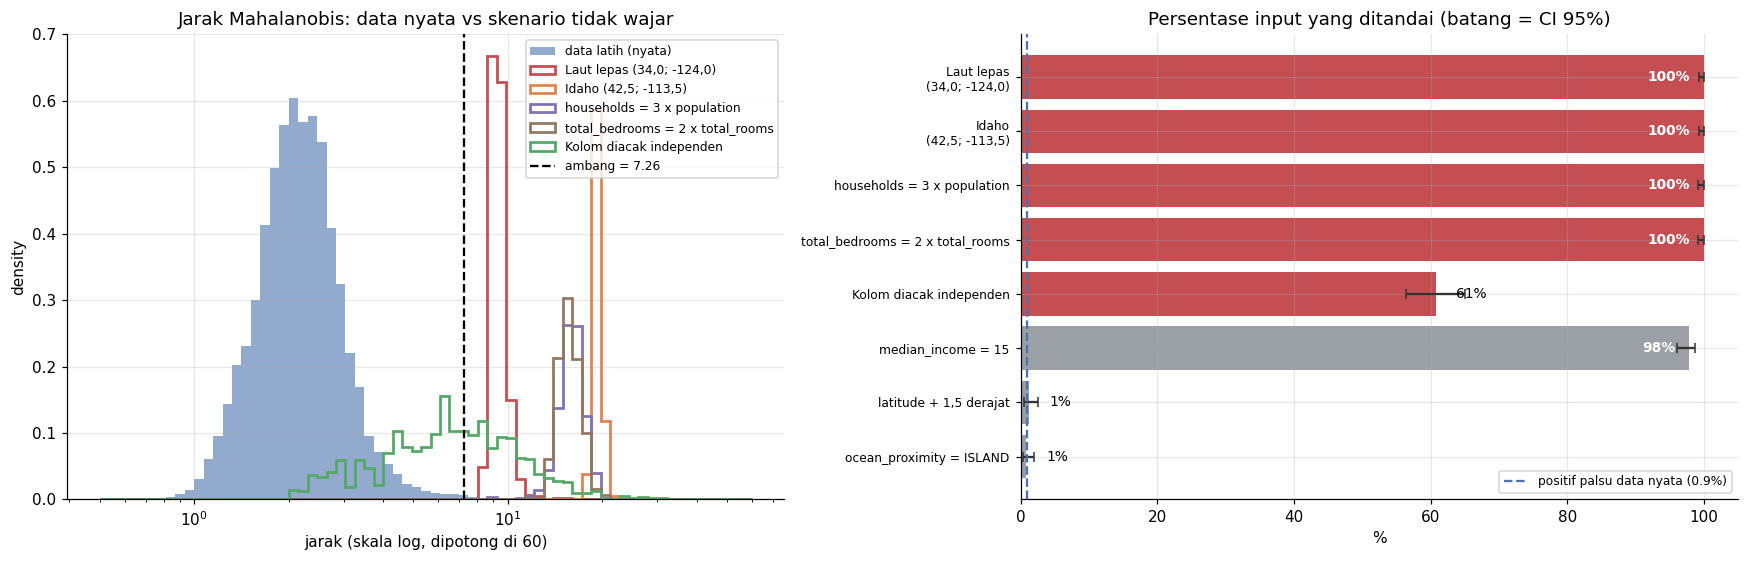

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
bins = np.logspace(np.log10(0.5), np.log10(60), 70)
ax[0].hist(DET.skor(Xn_train), bins=bins, density=True, color="#4C72B0", alpha=0.6, label="data latih (nyata)")
pal = {"Laut lepas (34,0; -124,0)": "#C44E52", "Idaho (42,5; -113,5)": "#DD8452", "households = 3 x population": "#8172B3",
       "total_bedrooms = 2 x total_rooms": "#937860", "Kolom diacak independen": "#55A868"}
for n, c in pal.items():
    ok = sk_test[n][2]
    if ok.any():
        ax[0].hist(np.clip(DET.skor(X_num(sk_test[n][1][ok])), 0.5, 60), bins=bins, density=True, histtype="step", lw=1.8, color=c, label=n)
if DET.thr:
    ax[0].axvline(DET.thr, color="black", ls="--", label=f"ambang = {DET.thr:.2f}")
ax[0].set_xscale("log")
ax[0].set(title="Jarak Mahalanobis: data nyata vs skenario tidak wajar", xlabel="jarak (skala log, dipotong di 60)", ylabel="density")
ax[0].legend(fontsize=8)

dd = det_tbl[det_tbl["kelompok"].isin(["tidak wajar", "halus"])].copy()
col = dd["kelompok"].map({"tidak wajar": "#C44E52", "halus": "#9aa0a6"})
yy = np.arange(len(dd))[::-1]
err = np.clip(np.vstack([dd["terpilih_%"] - dd["CI95_bawah"], dd["CI95_atas"] - dd["terpilih_%"]]), 0, None)
ax[1].barh(yy, dd["terpilih_%"], xerr=err, color=col, ecolor="#333", capsize=3)
ax[1].set_yticks(yy); ax[1].set_yticklabels([n.replace(" (", "\n(") for n in dd.index], fontsize=8)
ax[1].axvline(fpr_test, color="#4C72B0", ls="--", label=f"positif palsu data nyata ({fpr_test:.1f}%)")
for y, v in zip(yy, dd["terpilih_%"]):
    if v > 85:
        ax[1].text(v - 2, y, f"{v:.0f}%", va="center", ha="right", fontsize=9, color="white", fontweight="bold")
    else:
        ax[1].text(v + 3, y, f"{v:.0f}%", va="center", fontsize=9)
ax[1].set(title="Persentase input yang ditandai (batang = CI 95%)", xlabel="%", xlim=(0, 105))
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig("23_deteksi_di_luar_domain")
plt.show()

### 4.3 Kegagalan senyap: yang tampak wajar tetapi tidak boleh dipercaya

Dari input tidak wajar yang lolos API, berapa yang menghasilkan **prediksi yang tampak masuk akal**, dan berapa dari itu yang berhasil ditandai?
Inilah yang tanpa fitur ini tidak mungkin dibedakan oleh pengguna dari prediksi yang sah.

In [9]:
rows = []
for n in sc_tw:
    kel, s, ok = sk_test[n]
    if not ok.any():
        continue
    pr = prediksi_usd(s[ok]); f = DET.flag(X_num(s[ok]))
    wajar = (pr >= 15_000) & (pr <= 500_001)
    rows.append({"skenario": n, "n": int(ok.sum()), "tampak_wajar": int(wajar.sum()),
                 "tampak_wajar_dan_ditandai": int((wajar & f).sum()),
                 "lolos_tanpa_peringatan": int((wajar & ~f).sum())})
sil = pd.DataFrame(rows).set_index("skenario")
sil.loc["TOTAL"] = sil.sum()
display(sil)
tot = sil.loc["TOTAL"]
sil_caught = tot["tampak_wajar_dan_ditandai"] / tot["tampak_wajar"] * 100
sil_pass = tot["lolos_tanpa_peringatan"]
print(f"Dari {int(tot['tampak_wajar'])} prediksi yang tampak wajar tetapi berasal dari input tidak wajar, "
      f"{sil_caught:.1f}% diberi peringatan; {int(sil_pass)} lolos tanpa peringatan.")

,n,tampak_wajar,tampak_wajar_dan_ditandai,lolos_tanpa_peringatan
skenario,,,,
"Laut lepas (34,0; -124,0)",500,498,498,0
"Idaho (42,5; -113,5)",500,500,500,0
households = 3 x population,475,475,475,0
total_bedrooms = 2 x total_rooms,460,460,460,0
Kolom diacak independen,500,497,301,196
TOTAL,2435,2430,2234,196


Dari 2430 prediksi yang tampak wajar tetapi berasal dari input tidak wajar, 91.9% diberi peringatan; 196 lolos tanpa peringatan.


### 4.4 Apakah data nyata yang ditandai memang lebih sulit diprediksi?

In [10]:
pt = prediksi_usd(test_df)
ae = np.abs(pt - y_test)
fl = DET.flag(Xn_test)
mae_f, mae_n = ae[fl].mean(), ae[~fl].mean()

rng = np.random.default_rng(SEED)
bs = []
for _ in range(2000):
    a_ = rng.choice(ae[fl], size=fl.sum(), replace=True)
    b_ = rng.choice(ae[~fl], size=(~fl).sum(), replace=True)
    bs.append(a_.mean() - b_.mean())
ci = np.percentile(bs, [2.5, 97.5])
display(pd.DataFrame({"jumlah": [int(fl.sum()), int((~fl).sum())], "MAE_USD": [mae_f, mae_n]},
                     index=["ditandai di luar domain", "normal"]).round(0))
print(f"Selisih MAE: ${mae_f - mae_n:,.0f} | CI bootstrap 95%: [${ci[0]:,.0f}, ${ci[1]:,.0f}]")
mae_diff, mae_ci = mae_f - mae_n, ci

,jumlah,MAE_USD
ditandai di luar domain,29,45980.0
normal,3068,32899.0


Selisih MAE: $13,081 | CI bootstrap 95%: [$-660, $26,495]


Hanya sedikit baris test yang ditandai, sehingga selisih MAE ini punya ketidakpastian besar, dan selang bootstrap di atas menunjukkan seberapa besar.
Bagian ini dipakai sebagai **bukti pendukung**, bukan bukti utama: bukti utamanya adalah deteksi pada skenario yang memang sengaja dibuat tidak wajar
(bagian 4.2 dan 4.3), karena untuk input seperti itu tidak ada harga sebenarnya yang bisa dibandingkan.

### 4.5 Kestabilan: apakah hasil bergantung pada satu pembagian data?

Detektor dan ambang dilatih ulang pada `N_REPEAT` pembagian acak yang berbeda (70/15/15). Pada tiap pembagian diukur positif palsu pada bagian validation-nya
dan deteksi pada tiga skenario tidak wajar.

,FPR,"Laut lepas (34,0; -124,0)",households = 3 x population,Kolom diacak independen
mean,1.05,100.0,100.0,64.03
std,0.24,0.0,0.0,3.78
min,0.58,100.0,100.0,54.70
50%,1.05,100.0,100.0,63.64
max,1.68,100.0,100.0,73.06


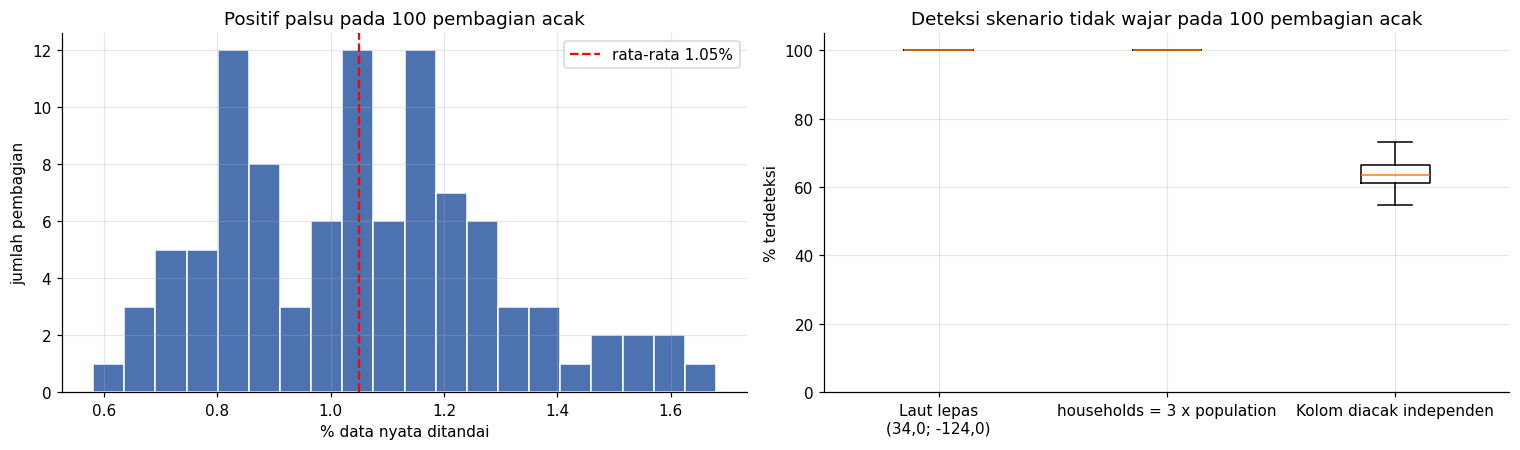

In [11]:
STAB = ["Laut lepas (34,0; -124,0)", "households = 3 x population", "Kolom diacak independen"]
fn_by = {nama: fn for nama, _, fn in SCEN}
a_, b_ = int(len(raw) * 0.70), int(len(raw) * 0.15)

def ulang(seed):
    rng = np.random.default_rng(seed)
    sh = raw.iloc[rng.permutation(len(raw))].reset_index(drop=True)
    tr, va = sh.iloc[:a_], sh.iloc[a_:a_ + b_].reset_index(drop=True)
    p = bp.fit_prep(tr)
    det = DomainDetector(DET.metode, DET.pct).fit(bp.transform(tr, p)[:, NUM_IDX])
    out = {"FPR": det.flag(bp.transform(va, p)[:, NUM_IDX]).mean() * 100}
    base = va.sample(300, random_state=seed).reset_index(drop=True)
    for n in STAB:
        s = fn_by[n](base.copy(), rng); ok = lolos_validasi(s)
        out[n] = det.flag(bp.transform(s[ok], p)[:, NUM_IDX]).mean() * 100 if ok.any() else np.nan
    return out

stab = pd.DataFrame([ulang(1000 + i) for i in range(N_REPEAT)])
display(stab.describe().loc[["mean", "std", "min", "50%", "max"]].round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(stab["FPR"], bins=20, color="#4C72B0", edgecolor="white")
ax[0].axvline(stab["FPR"].mean(), color="red", ls="--", label=f"rata-rata {stab['FPR'].mean():.2f}%")
ax[0].set(title=f"Positif palsu pada {N_REPEAT} pembagian acak", xlabel="% data nyata ditandai", ylabel="jumlah pembagian"); ax[0].legend()
ax[1].boxplot([stab[n].dropna() for n in STAB], labels=[n.replace(" (", "\n(") for n in STAB])
ax[1].set(title=f"Deteksi skenario tidak wajar pada {N_REPEAT} pembagian acak", ylabel="% terdeteksi", ylim=(0, 105))
plt.tight_layout()
save_fig("24_kestabilan_deteksi")
plt.show()

### 4.6 Contoh keluaran

In [12]:
contoh = pd.concat([
    test_df.iloc[[0]].assign(ket="blok asli"),
    test_df.iloc[[1]].assign(ket="blok asli"),
    test_df.iloc[[2]].assign(ket="lokasi di laut lepas", latitude=34.0, longitude=-124.0),
    test_df.iloc[[3]].assign(ket="households = 3 x population", households=lambda d: d["population"] * 3),
    test_df.iloc[[4]].assign(ket="total_bedrooms = 2 x total_rooms", total_bedrooms=lambda d: d["total_rooms"] * 2),
], ignore_index=True)
assert lolos_validasi(contoh).all(), "contoh harus lolos validasi API"
out = cek_domain(contoh)
out.insert(0, "keterangan", contoh["ket"].values)
out.insert(1, "prediksi_USD", prediksi_usd(contoh).round(0))
out.insert(2, "harga_asli_USD", contoh[TARGET].values)
display(out)

,keterangan,prediksi_USD,harga_asli_USD,skor,ambang,status,penyebab
0,blok asli,265245.0,296200.0,2.25,7.264027,NORMAL,-
1,blok asli,172581.0,190000.0,1.59,7.264027,NORMAL,-
2,lokasi di laut lepas,121335.0,90400.0,9.57,7.264027,DI LUAR DOMAIN,"longitude, latitude"
3,households = 3 x population,101441.0,48500.0,17.63,7.264027,DI LUAR DOMAIN,"households, total_rooms"
4,total_bedrooms = 2 x total_rooms,186221.0,265200.0,16.65,7.264027,DI LUAR DOMAIN,"total_bedrooms, median_income"


`penyebab` adalah dua fitur dengan sumbangan terbesar pada jarak, **bukan selalu fitur yang diubah**, karena fitur-fitur saling berkorelasi
(pada contoh terakhir, `median_income` ikut muncul karena nilainya tidak lazim bila dipasangkan dengan jumlah kamar tidur itu).
Pesan peringatan di aplikasi sebaiknya berbunyi "kombinasi nilai ini tidak lazim, terutama pada ...", bukan "fitur ini salah".

## 5. Penyimpanan dan Integrasi ke Aplikasi

Parameter detektor disimpan ke `data/processed/ood.json`, termasuk **SHA-256 file `prep.json`** yang dipakai. Detektor bekerja pada fitur terstandardisasi,
sehingga hanya sah untuk preprocessing yang sama persis. Jika `prep.json` berubah (misalnya model dilatih ulang), detektor harus dilatih ulang
dengan menjalankan notebook ini lagi.

In [13]:
params = {
    "tanggal": str(date.today()), "metode": DET.metode, "persentil": DET.pct, "ambang": DET.thr,
    "fitur_numerik": NUM_NAMES, "mean": DET.mu.tolist(), "precision": DET.P.tolist(),
    "min": DET.lo.tolist(), "max": DET.hi.tolist(),
    "fpr_validation_persen": float(sel.loc[best_name, "FPR_val_%"]),
    "prep_sha256": hashlib.sha256((ART / "prep.json").read_bytes()).hexdigest(),
}
(MODEL_DIR / "ood.json").write_text(json.dumps(params, indent=2))


def cek_domain_dari_params(params, Xnum):
    """Versi murni NumPy (tanpa kelas, tanpa Keras): inilah yang disalin ke backend/app.py."""
    mu, P = np.array(params["mean"]), np.array(params["precision"])
    d = Xnum - mu
    skor = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", d, P, d), 0.0))
    luar = ((Xnum < np.array(params["min"])) | (Xnum > np.array(params["max"]))).any(axis=1)
    if params["metode"] == "rentang":
        flag = luar
    else:
        flag = skor > params["ambang"]
        if params["metode"] == "gabungan":
            flag = flag | luar
    return skor, flag


# Pastikan versi yang disimpan identik dengan kelas di notebook
p2 = json.loads((MODEL_DIR / "ood.json").read_text())
s2, f2 = cek_domain_dari_params(p2, Xn_test)
assert np.allclose(s2, DET.skor(Xn_test), atol=1e-6) and (f2 == DET.flag(Xn_test)).all()
print("data/processed/ood.json:", (MODEL_DIR / "ood.json").stat().st_size, "byte | hasil identik dengan DomainDetector: True")
print("SHA-256 prep.json:", params["prep_sha256"][:16], "...")

data/processed/ood.json: 2844 byte | hasil identik dengan DomainDetector: True
SHA-256 prep.json: 4f223d7019f6cbe5 ...


**Cara memasangnya di aplikasi** (belum dilakukan di notebook ini, agar `backend/` tidak berubah tanpa Anda sadari):

1. Salin `data/processed/ood.json` ke `backend/artifacts/` dan fungsi `cek_domain_dari_params` ke `backend/app.py`.
2. Muat JSON saat startup. Di endpoint `/api/predict`, setelah `transform(...)`, panggil fungsi itu pada 8 kolom pertama (`x[:, :8]`).
3. Tambahkan `"di_luar_domain": bool(flag[0])` dan `"skor_domain": float(skor[0])` pada respons. **Prediksi tetap dikembalikan**, karena fitur ini memberi peringatan, bukan penolakan.
4. Di `frontend/`, tampilkan peringatan di bawah angka utama bila `di_luar_domain` bernilai `true`.
5. **Pastikan `backend/artifacts/prep.json` sama dengan yang dipakai detektor.** Bandingkan SHA-256 file itu dengan `prep_sha256` di JSON.

Fitur ini dapat dipakai bersama interval prediksi dari notebook 05: interval menjawab "seberapa besar kemungkinan meleset", sedangkan
deteksi ini menjawab "apakah input ini pantas diprediksi sama sekali".

## 6. Kesimpulan Otomatis

Sel di bawah menyusun kesimpulan dari angka yang benar-benar dihitung di atas, sehingga selalu cocok dengan tabel.

In [14]:
tw = det_tbl[det_tbl["kelompok"] == "tidak wajar"]
hs = det_tbl[det_tbl["kelompok"] == "halus"]
ctrl = det_tbl.loc["Kontrol: data asli"]

L = []
L.append(f"**Metode terpilih (dari validation):** `{best_name}`" + (f", ambang jarak {DET.thr:.2f}." if DET.thr else "."))
L.append("")
L.append("**Bukti dampak**")
L.append(f"- **Positif palsu:** {fpr_test:.2f}% data test nyata ditandai (CI 95%: {fpr_tbl.loc['test','CI95_bawah']:.2f}% sampai "
         f"{fpr_tbl.loc['test','CI95_atas']:.2f}%). Pada {N_REPEAT} pembagian acak, rata-ratanya {stab['FPR'].mean():.2f}% "
         f"(rentang {stab['FPR'].min():.2f}% sampai {stab['FPR'].max():.2f}%).")
L.append("- **Deteksi input tidak wajar yang lolos API:** " + "; ".join(f"{n} {r['terpilih_%']:.0f}%" for n, r in tw.iterrows()) + ".")
L.append(f"  Pemeriksaan rentang per fitur (versi ketat dari data latih) hanya menangkap "
         f"{tw['rentang_train_%'].mean():.0f}% pada skenario yang sama (rata-rata), jadi nilai tambah berasal dari memeriksa **kombinasi** fitur.")
L.append(f"- **Kegagalan senyap:** dari {int(tot['tampak_wajar'])} prediksi yang tampak wajar tetapi berasal dari input tidak wajar, "
         f"{sil_caught:.1f}% diberi peringatan dan {int(sil_pass)} lolos tanpa peringatan.")
L.append(f"- **Data nyata yang ditandai:** MAE ${mae_f:,.0f} vs ${mae_n:,.0f} pada yang normal "
         f"(selisih ${mae_diff:,.0f}, CI bootstrap 95% [${mae_ci[0]:,.0f}, ${mae_ci[1]:,.0f}]; hanya {int(fl.sum())} baris ditandai)."
         + (" Selang itu mencakup nol, sehingga selisih ini **belum dapat dipastikan** dan hanya menjadi bukti pendukung." if mae_ci[0] <= 0 else ""))
L.append("")
L.append("**Batasan yang perlu diketahui**")
miss_h = [f"{n} ({r['terpilih_%']:.0f}%)" for n, r in hs.iterrows() if r["terpilih_%"] < 50]
hit_h = [f"{n} ({r['terpilih_%']:.0f}%)" for n, r in hs.iterrows() if r["terpilih_%"] >= 50]
L.append("- **Kasus halus: hasil campuran.** Tidak tertangkap: " + (", ".join(miss_h) or "tidak ada") +
         ". Tertangkap: " + (", ".join(hit_h) or "tidak ada") + ". Detektor ini menangkap nilai atau kombinasi yang jauh dari data latih, bukan pergeseran kecil atau ketidakcocokan kategori.")
acak_pct = float(tw.loc["Kolom diacak independen", "terpilih_%"])
L.append(f"- Pada skenario kolom diacak, sekitar {100 - acak_pct:.0f}% input tidak tertangkap karena sebagian kombinasi acak kebetulan masih lazim; ini juga sumber "
         f"{int(sil_pass)} prediksi yang lolos tanpa peringatan.")
L.append(f"- Sekitar {fpr_test:.1f}% input yang sebenarnya wajar ikut ditandai. Itu harga dari ambang; karena fitur ini hanya memberi peringatan dan tidak memblokir, dampaknya ringan.")
L.append("- Skenario dibuat sintetis oleh pembuat notebook, bukan input nyata dari pengguna. Hasilnya menunjukkan kemampuan mendeteksi **jenis** keanehan yang diuji, bukan jaminan untuk semua jenis.")
L.append("- Hanya 8 fitur numerik diperiksa. **Ketidakcocokan kategori dengan lokasi** (misalnya `ISLAND` di koordinat daratan) tidak terdeteksi, seperti terlihat pada skenario halus.")
L.append("- Mahalanobis mengasumsikan sebaran data kira-kira berbentuk elips. Lokasi di California membentuk beberapa gugus (misalnya Bay Area dan Los Angeles), sehingga titik di antara gugus bisa lolos; ini tidak diuji secara khusus di sini.")
L.append("- Deteksi hanya menilai **input**, bukan benar-tidaknya prediksi. Input normal tetap bisa meleset (lihat galat model di notebook 03 dan interval di notebook 05).")
display(Markdown("\n".join(L)))

**Metode terpilih (dari validation):** `mahalanobis_p99`, ambang jarak 7.26.

**Bukti dampak**
- **Positif palsu:** 0.94% data test nyata ditandai (CI 95%: 0.65% sampai 1.34%). Pada 100 pembagian acak, rata-ratanya 1.05% (rentang 0.58% sampai 1.68%).
- **Deteksi input tidak wajar yang lolos API:** Laut lepas (34,0; -124,0) 100%; Idaho (42,5; -113,5) 100%; households = 3 x population 100%; total_bedrooms = 2 x total_rooms 100%; Kolom diacak independen 61%.
  Pemeriksaan rentang per fitur (versi ketat dari data latih) hanya menangkap 26% pada skenario yang sama (rata-rata), jadi nilai tambah berasal dari memeriksa **kombinasi** fitur.
- **Kegagalan senyap:** dari 2430 prediksi yang tampak wajar tetapi berasal dari input tidak wajar, 91.9% diberi peringatan dan 196 lolos tanpa peringatan.
- **Data nyata yang ditandai:** MAE $45,980 vs $32,899 pada yang normal (selisih $13,081, CI bootstrap 95% [$-660, $26,495]; hanya 29 baris ditandai). Selang itu mencakup nol, sehingga selisih ini **belum dapat dipastikan** dan hanya menjadi bukti pendukung.

**Batasan yang perlu diketahui**
- **Kasus halus: hasil campuran.** Tidak tertangkap: latitude + 1,5 derajat (1%), ocean_proximity = ISLAND (1%). Tertangkap: median_income = 15 (98%). Detektor ini menangkap nilai atau kombinasi yang jauh dari data latih, bukan pergeseran kecil atau ketidakcocokan kategori.
- Pada skenario kolom diacak, sekitar 39% input tidak tertangkap karena sebagian kombinasi acak kebetulan masih lazim; ini juga sumber 196 prediksi yang lolos tanpa peringatan.
- Sekitar 0.9% input yang sebenarnya wajar ikut ditandai. Itu harga dari ambang; karena fitur ini hanya memberi peringatan dan tidak memblokir, dampaknya ringan.
- Skenario dibuat sintetis oleh pembuat notebook, bukan input nyata dari pengguna. Hasilnya menunjukkan kemampuan mendeteksi **jenis** keanehan yang diuji, bukan jaminan untuk semua jenis.
- Hanya 8 fitur numerik diperiksa. **Ketidakcocokan kategori dengan lokasi** (misalnya `ISLAND` di koordinat daratan) tidak terdeteksi, seperti terlihat pada skenario halus.
- Mahalanobis mengasumsikan sebaran data kira-kira berbentuk elips. Lokasi di California membentuk beberapa gugus (misalnya Bay Area dan Los Angeles), sehingga titik di antara gugus bisa lolos; ini tidak diuji secara khusus di sini.
- Deteksi hanya menilai **input**, bukan benar-tidaknya prediksi. Input normal tetap bisa meleset (lihat galat model di notebook 03 dan interval di notebook 05).